# Preprocessing & Feature Engineering

**Project:** MarketPulse Ghana
**Phase:** 2 of 5
**Depends on:** `agri_ghana.duckdb` (table `raw_wfp_prices`)

## Purpose

This notebook converts the raw WFP snapshot into a clean, model-ready dataset for
forecasting Ghana's national monthly median wholesale maize price one month ahead.

The modelling target was chosen based on EDA findings (Phase 1):

| Criterion | Retail Maize (KG) | Wholesale Maize (100 KG) | Decision |
|-----------|------------------|--------------------------|----------|
| Months of history | 48 (Aug 2019 - Jul 2023) | 209 (Jan 2006 - Jul 2023) | Wholesale |
| Markets per month | ~18 | ~10 growing to 17 | Comparable |

A lag-12 model applied to 48 retail months would retain fewer than 36 usable training
rows, which is insufficient for reliable generalisation. The wholesale series provides
209 months and a substantially larger training window.
Prices are normalised to GHS per kg to ensure comparability across analyses.

## Scope

- The database preserves the raw WFP table; this notebook does **not** modify it.
- Outlier records flagged in Phase 1 are reviewed and handled transparently.
- The final feature matrix and target vector are saved to `data/`.

## Sections

1. Setup
2. Extract target series
3. Data cleaning
4. Feature engineering
5. Feature selection
6. Data transformation
7. Train / test split
8. Save outputs
9. Summary

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import duckdb
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path

# Paths
PROJECT_ROOT = Path("..").resolve()
DB_PATH      = PROJECT_ROOT / "agri_ghana.duckdb"
DATA_DIR     = PROJECT_ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)

# Plot style
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "font.size": 11,
})
PALETTE = sns.color_palette("muted")

# DuckDB (read-only)
con = duckdb.connect(str(DB_PATH), read_only=True)
print("Connected to", DB_PATH.name)

Connected to agri_ghana.duckdb


## 2. Extract Target Series

This section extracts the national monthly median wholesale maize price (100 KG unit)
and converts it to GHS per kg. All downstream calculations use the per-kg scale.

In [2]:
QUERY = """
    SELECT
        DATE_TRUNC('month', date)::DATE  AS month,
        COUNT(DISTINCT market)           AS n_markets,
        MEDIAN(price)                    AS median_price_100kg,
        MEDIAN(usdprice)                 AS median_usd_100kg
    FROM raw_wfp_prices
    WHERE commodity  = 'Maize'
      AND pricetype  = 'Wholesale'
      AND unit       = '100 KG'
    GROUP BY 1
    ORDER BY 1
"""

raw = con.execute(QUERY).df()
raw["month"] = pd.to_datetime(raw["month"])
raw = raw.set_index("month").sort_index()

# Convert to per-kg
raw["price_ghs"] = raw["median_price_100kg"] / 100
raw["price_usd"] = raw["median_usd_100kg"]   / 100

print(f"Series length : {len(raw)} months")
print(f"Date range    : {raw.index.min().date()} to {raw.index.max().date()}")
print(f"Markets/month : min={raw.n_markets.min()}, median={raw.n_markets.median()}, max={raw.n_markets.max()}")
raw[["price_ghs", "n_markets"]].head()

Series length : 209 months
Date range    : 2006-01-01 to 2023-07-01
Markets/month : min=4, median=13.0, max=43


,price_ghs,n_markets
month,,
2006-01-01,0.21700,6
2006-02-01,0.21750,5
2006-03-01,0.21305,6
2006-04-01,0.19810,6
2006-05-01,0.20220,6


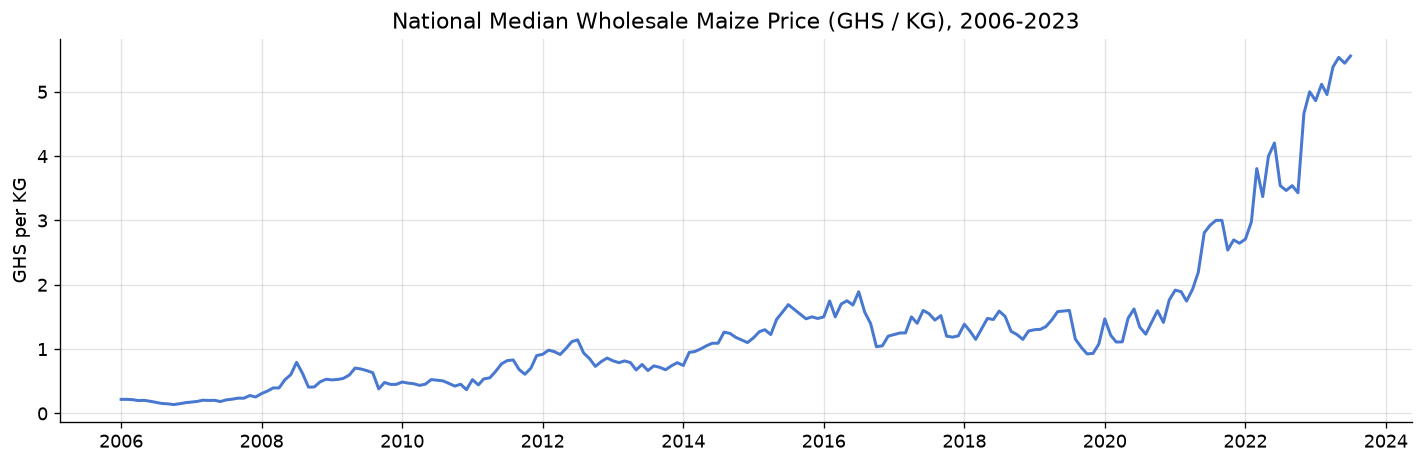

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(raw.index, raw["price_ghs"], color=PALETTE[0], linewidth=1.8)
ax.set_title("National Median Wholesale Maize Price (GHS / KG), 2006-2023")
ax.set_ylabel("GHS per KG")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

## 3. Data Cleaning

### 3.1 Check for gaps in the monthly series

A lag-based model requires a complete, evenly-spaced time index. Any missing months
must be identified and handled before features are built.

In [4]:
full_idx = pd.date_range(raw.index.min(), raw.index.max(), freq="MS")
missing  = full_idx.difference(raw.index)

print(f"Expected months : {len(full_idx)}")
print(f"Present months  : {len(raw)}")
print(f"Missing months  : {len(missing)}")
if len(missing):
    print("Missing dates:")
    print(missing)

Expected months : 211
Present months  : 209
Missing months  : 2
Missing dates:
DatetimeIndex(['2015-08-01', '2015-09-01'], dtype='datetime64[us]', freq='MS')


### 3.2 Reindex and fill any gaps

Short gaps (up to 3 months) are filled by linear interpolation.
Longer gaps are forward-filled and flagged with an `imputed` column.

In [5]:
df = raw[["price_ghs", "n_markets"]].copy()
df = df.reindex(full_idx)

# Always initialise imputed=0 so the column exists regardless of which branch runs
df["imputed"] = 0

n_filled = df["price_ghs"].isna().sum()

if n_filled > 0:
    if n_filled <= 3:
        df["price_ghs"] = df["price_ghs"].interpolate(method="time")
        df["n_markets"]  = df["n_markets"].interpolate(method="time").round()
        print(f"Filled {n_filled} month(s) by linear interpolation.")
    else:
        df.loc[df["price_ghs"].isna(), "imputed"] = 1
        df["price_ghs"] = df["price_ghs"].ffill()
        df["n_markets"]  = df["n_markets"].ffill()
        print(f"WARNING: {n_filled} missing months forward-filled and flagged.")
    print(f"Missing months identified: {n_filled}")
else:
    print("No gaps -- series is complete.")

print(f"Final series length: {len(df)} rows")

Filled 2 month(s) by linear interpolation.
Missing months identified: 2
Final series length: 211 rows


### 3.3 Outlier review

A rolling 12-month IQR fence (3×) is applied at the aggregated series level.
Flagged months are **not removed**—they are retained and noted for interpretive context.
Aggregation already dampens individual market-level anomalies.

In [6]:
roll_med = df["price_ghs"].rolling(12, min_periods=6).median()
roll_iqr = (
    df["price_ghs"].rolling(12, min_periods=6).quantile(0.75)
    - df["price_ghs"].rolling(12, min_periods=6).quantile(0.25)
)

lower_fence = roll_med - 3 * roll_iqr
upper_fence = roll_med + 3 * roll_iqr

df["outlier_flag"] = (
    (df["price_ghs"] < lower_fence) | (df["price_ghs"] > upper_fence)
).astype(int)

n_flags = df["outlier_flag"].sum()
print(f"Months flagged as potential outliers: {n_flags}")
if n_flags > 0:
    print(df[df["outlier_flag"] == 1][["price_ghs", "n_markets"]])

Months flagged as potential outliers: 1
            price_ghs  n_markets
2015-06-01      1.575       15.0


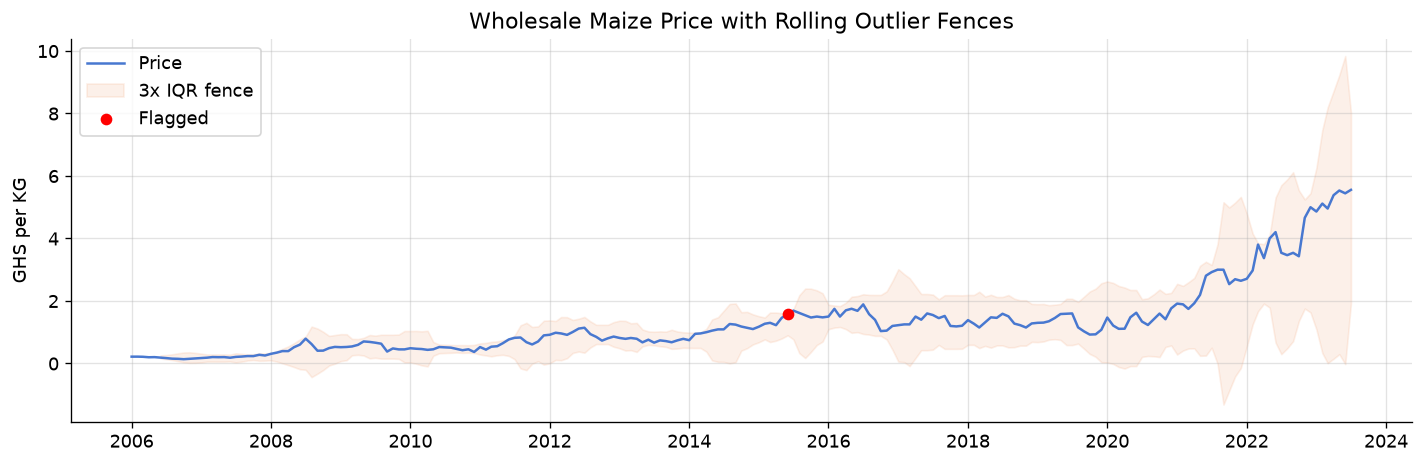

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df["price_ghs"], color=PALETTE[0], linewidth=1.5, label="Price")
ax.fill_between(df.index, lower_fence, upper_fence,
                alpha=0.12, color=PALETTE[1], label="3x IQR fence")
if n_flags > 0:
    flagged = df[df["outlier_flag"] == 1]
    ax.scatter(flagged.index, flagged["price_ghs"],
               color="red", zorder=5, label="Flagged")
ax.set_title("Wholesale Maize Price with Rolling Outlier Fences")
ax.set_ylabel("GHS per KG")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Feature Engineering

Four groups of features, all derived from the cleaned price series and the calendar.
No external data is introduced. Every feature is computed at time *t* to predict
the price at time *t+1*.

| Group | Features | Rationale |
|-------|----------|-----------|
| Lag prices | t-1, t-2, t-3, t-6, t-12 | Direct price memory |
| Rolling stats | 3/6/12-month mean, 3-month std | Trend and volatility |
| Calendar | month (sin/cos), quarter, year | Seasonality and drift |
| Derived | Month-on-month and year-on-year percentage change | Momentum signal |

### 4.1 Lag features

In [8]:
for lag in [1, 2, 3, 6, 12]:
    df[f"lag_{lag}"] = df["price_ghs"].shift(lag)

print("Lag features added: lag_1, lag_2, lag_3, lag_6, lag_12")
df[["price_ghs", "lag_1", "lag_2", "lag_3", "lag_6", "lag_12"]].tail()

Lag features added: lag_1, lag_2, lag_3, lag_6, lag_12


,price_ghs,lag_1,lag_2,lag_3,lag_6,lag_12
2023-03-01,4.9569,5.1163,4.8615,4.9998,3.5403,3.80500
2023-04-01,5.3846,4.9569,5.1163,4.8615,3.4301,3.37000
2023-05-01,5.5342,5.3846,4.9569,5.1163,4.6609,4.00000
2023-06-01,5.4444,5.5342,5.3846,4.9569,4.9998,4.20315
2023-07-01,5.5556,5.4444,5.5342,5.3846,4.8615,3.54030


### 4.2 Rolling statistics

In [9]:
# Shift by 1 so we only use information available at time t
p_shifted = df["price_ghs"].shift(1)

df["roll_mean_3"]  = p_shifted.rolling(3).mean()
df["roll_std_3"]   = p_shifted.rolling(3).std()
df["roll_mean_6"]  = p_shifted.rolling(6).mean()
df["roll_mean_12"] = p_shifted.rolling(12).mean()

print("Rolling features added: roll_mean_3, roll_std_3, roll_mean_6, roll_mean_12")

Rolling features added: roll_mean_3, roll_std_3, roll_mean_6, roll_mean_12


### 4.3 Calendar features

In [10]:
df["month_num"] = df.index.month
df["quarter"]   = df.index.quarter
df["year"]      = df.index.year

# Cyclical encoding so January and December are adjacent in feature space
df["month_sin"] = np.sin(2 * np.pi * df["month_num"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month_num"] / 12)

print("Calendar features added: month_num, quarter, year, month_sin, month_cos")

Calendar features added: month_num, quarter, year, month_sin, month_cos


### 4.4 Rate-of-change features

In [11]:
df["pct_change_1m"]  = df["price_ghs"].pct_change(1).shift(1)   # MoM at t-1
df["pct_change_12m"] = df["price_ghs"].pct_change(12).shift(1)  # YoY at t-1

print("Rate-of-change features added: pct_change_1m, pct_change_12m")

Rate-of-change features added: pct_change_1m, pct_change_12m


### 4.5 Define the forecast target

The target is the price at *t+1*: the next month's national median wholesale maize
price in GHS per KG.

In [12]:
df["target"] = df["price_ghs"].shift(-1)

print("Target column: target = price_ghs shifted forward by 1 month")
print("The last row will have NaN target and will be dropped in Section 5.")

Target column: target = price_ghs shifted forward by 1 month
The last row will have NaN target and will be dropped in Section 5.


## 5. Feature Selection

### 5.1 Redundant columns from EDA

Phase 1 (Section 10.1) confirmed:
- `usdprice` is a linear transformation of `price` via the exchange rate.
- `market_id`, `commodity_id`, `latitude`, `longitude` duplicate name columns.

These do not appear in the aggregated feature matrix.

### 5.2 Drop warm-up rows

The longest lag is 12 months; the 12-month rolling mean requires an additional
11-row warm-up period. All rows in which any feature or the target is NaN are removed.

In [13]:
FEATURE_COLS = [
    # Lags
    "lag_1", "lag_2", "lag_3", "lag_6", "lag_12",
    # Rolling
    "roll_mean_3", "roll_std_3", "roll_mean_6", "roll_mean_12",
    # Calendar
    "month_sin", "month_cos", "quarter", "year",
    # Rate of change
    "pct_change_1m", "pct_change_12m",
    # Market depth (data confidence proxy)
    "n_markets",
]
TARGET_COL = "target"

model_df = df[FEATURE_COLS + [TARGET_COL, "price_ghs", "outlier_flag", "imputed"]].copy()
before   = len(model_df)
model_df = model_df.dropna(subset=FEATURE_COLS + [TARGET_COL])
after    = len(model_df)

print(f"Rows before drop : {before}")
print(f"Rows after drop  : {after}  ({before - after} warm-up rows removed)")
print(f"Usable range     : {model_df.index.min().date()} to {model_df.index.max().date()}")
print(f"\nFeatures ({len(FEATURE_COLS)}):")
for f in FEATURE_COLS:
    print(f"  {f}")

Rows before drop : 211
Rows after drop  : 197  (14 warm-up rows removed)
Usable range     : 2007-02-01 to 2023-06-01

Features (16):
  lag_1
  lag_2
  lag_3
  lag_6
  lag_12
  roll_mean_3
  roll_std_3
  roll_mean_6
  roll_mean_12
  month_sin
  month_cos
  quarter
  year
  pct_change_1m
  pct_change_12m
  n_markets


### 5.3 Feature correlation heatmap

Pairs with |r| >= 0.95 are candidates for removal. Lag features are expected to be
highly correlated; tree-based models handle this naturally via split selection.

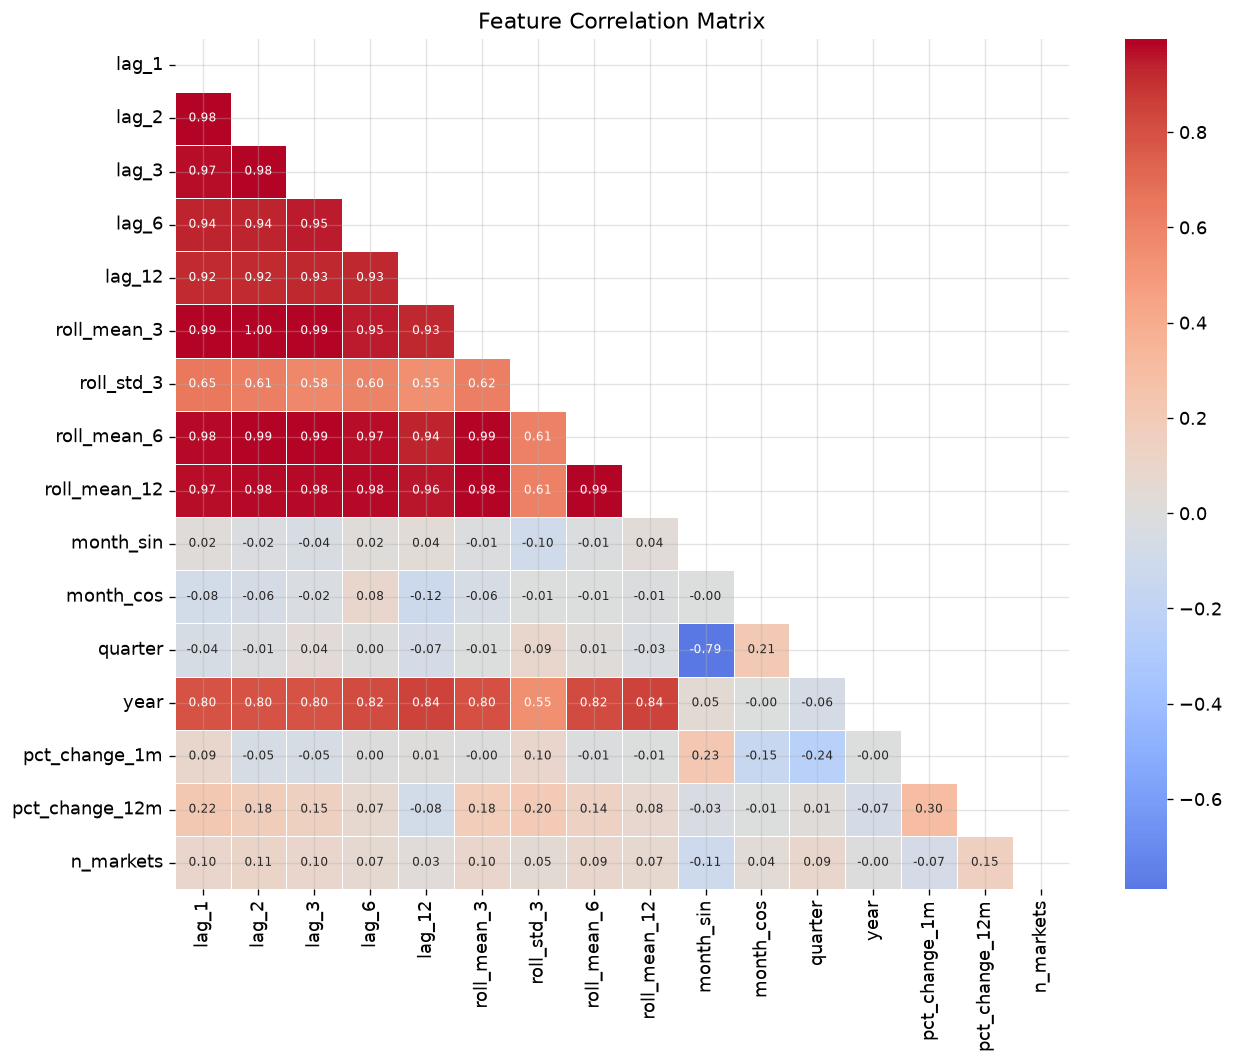

Highly correlated pairs (|r| >= 0.95):
  lag_2 vs roll_mean_3: 0.996
  roll_mean_3 vs roll_mean_6: 0.993
  roll_mean_6 vs roll_mean_12: 0.993
  lag_1 vs roll_mean_3: 0.992
  lag_3 vs roll_mean_3: 0.991
  lag_3 vs roll_mean_6: 0.990
  lag_2 vs roll_mean_6: 0.987
  roll_mean_3 vs roll_mean_12: 0.984
  lag_1 vs lag_2: 0.984
  lag_2 vs lag_3: 0.983
  lag_1 vs roll_mean_6: 0.982
  lag_3 vs roll_mean_12: 0.980
  lag_2 vs roll_mean_12: 0.978
  lag_6 vs roll_mean_12: 0.977
  lag_1 vs roll_mean_12: 0.975
  lag_6 vs roll_mean_6: 0.975
  lag_1 vs lag_3: 0.969
  lag_12 vs roll_mean_12: 0.960


In [14]:
corr = model_df[FEATURE_COLS].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, linewidths=0.4, ax=ax, annot_kws={"size": 7}
)
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

high_corr = [
    (c1, c2, corr.loc[c1, c2])
    for i, c1 in enumerate(FEATURE_COLS)
    for c2 in FEATURE_COLS[i+1:]
    if abs(corr.loc[c1, c2]) >= 0.95
]
if high_corr:
    print("Highly correlated pairs (|r| >= 0.95):")
    for c1, c2, r in sorted(high_corr, key=lambda x: -abs(x[2])):
        print(f"  {c1} vs {c2}: {r:.3f}")
else:
    print("No feature pairs with |r| >= 0.95.")

### 5.4 Correlation with target

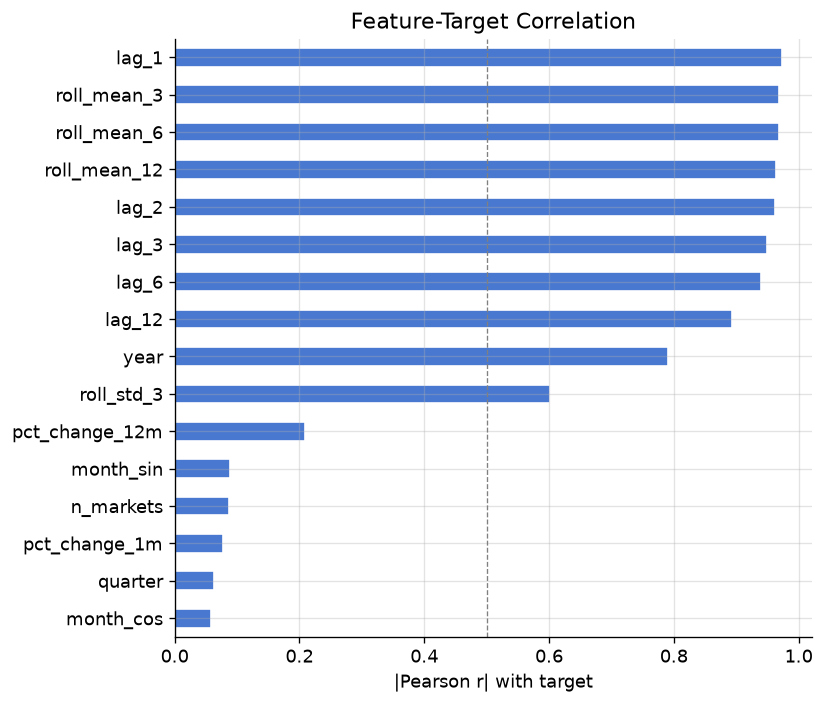

In [15]:
target_corr = (
    model_df[FEATURE_COLS + [TARGET_COL]]
    .corr()[TARGET_COL]
    .drop(TARGET_COL)
    .abs()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(7, 6))
target_corr.plot.barh(ax=ax, color=PALETTE[0], edgecolor="white")
ax.set_xlabel("|Pearson r| with target")
ax.set_title("Feature-Target Correlation")
ax.axvline(0.5, color="grey", linestyle="--", linewidth=0.8)
plt.tight_layout()
plt.show()

## 6. Data Transformation

### 6.1 Log transformation of price features

Phase 1 (Section 7) showed that price distributions are right-skewed and that
`log1p` substantially reduces skewness. All price-level features (lags, rolling
means) and the target are log-transformed.

Rate-of-change and calendar features are left on their natural scale.
Predictions are exponentiated back to GHS/KG in Phase 4.

In [16]:
PRICE_LEVEL_FEATURES = [
    "lag_1", "lag_2", "lag_3", "lag_6", "lag_12",
    "roll_mean_3", "roll_mean_6", "roll_mean_12",
]

for col in PRICE_LEVEL_FEATURES:
    model_df[f"log_{col}"] = np.log1p(model_df[col])

model_df["log_target"] = np.log1p(model_df[TARGET_COL])

FINAL_FEATURES = (
    [f"log_{c}" for c in PRICE_LEVEL_FEATURES]
    + ["roll_std_3", "month_sin", "month_cos", "quarter", "year",
       "pct_change_1m", "pct_change_12m", "n_markets"]
)

print(f"Final feature count : {len(FINAL_FEATURES)}")
for f in FINAL_FEATURES:
    print(f"  {f}")

Final feature count : 16
  log_lag_1
  log_lag_2
  log_lag_3
  log_lag_6
  log_lag_12
  log_roll_mean_3
  log_roll_mean_6
  log_roll_mean_12
  roll_std_3
  month_sin
  month_cos
  quarter
  year
  pct_change_1m
  pct_change_12m
  n_markets


In [17]:
nan_counts = model_df[FINAL_FEATURES + ["log_target"]].isna().sum()
nan_counts = nan_counts[nan_counts > 0]
if len(nan_counts) == 0:
    print("No NaN values in final feature matrix or target.")
else:
    print("NaN values found -- review before training:")
    print(nan_counts)

No NaN values in final feature matrix or target.


### 6.2 Note on scaling

XGBoost is invariant to monotonic feature scaling, so standardisation is **not
required** and is omitted. If a linear baseline is tested in a later phase,
scaling must be fitted on training data only and applied to the test set.

## 7. Train / Test Split

### 7.1 Chronological split

Time-series data must be split chronologically to prevent future data from leaking
into training. A random split would give optimistically misleading scores.

The final 18 months are reserved as the held-out test set.

- Test window covers the 2022 high-inflation spike and partial 2023 stabilisation
  —a rigorous evaluation covering conditions not represented in training.
- Training covers nearly 16 years, giving the model a full seasonal cycle and two
  major price regimes to learn from.

In [18]:
TEST_MONTHS = 18
split_date  = model_df.index[-TEST_MONTHS]

train = model_df[model_df.index < split_date].copy()
test  = model_df[model_df.index >= split_date].copy()

X_train = train[FINAL_FEATURES]
y_train = train["log_target"]
X_test  = test[FINAL_FEATURES]
y_test  = test["log_target"]

print(f"Split date        : {split_date.date()}")
print(f"Training rows     : {len(train)}  ({train.index.min().date()} to {train.index.max().date()})")
print(f"Test rows         : {len(test)}   ({test.index.min().date()} to {test.index.max().date()})")
print(f"Train/Test ratio  : {len(train)/len(model_df):.1%} / {len(test)/len(model_df):.1%}")

Split date        : 2022-01-01
Training rows     : 179  (2007-02-01 to 2021-12-01)
Test rows         : 18   (2022-01-01 to 2023-06-01)
Train/Test ratio  : 90.9% / 9.1%


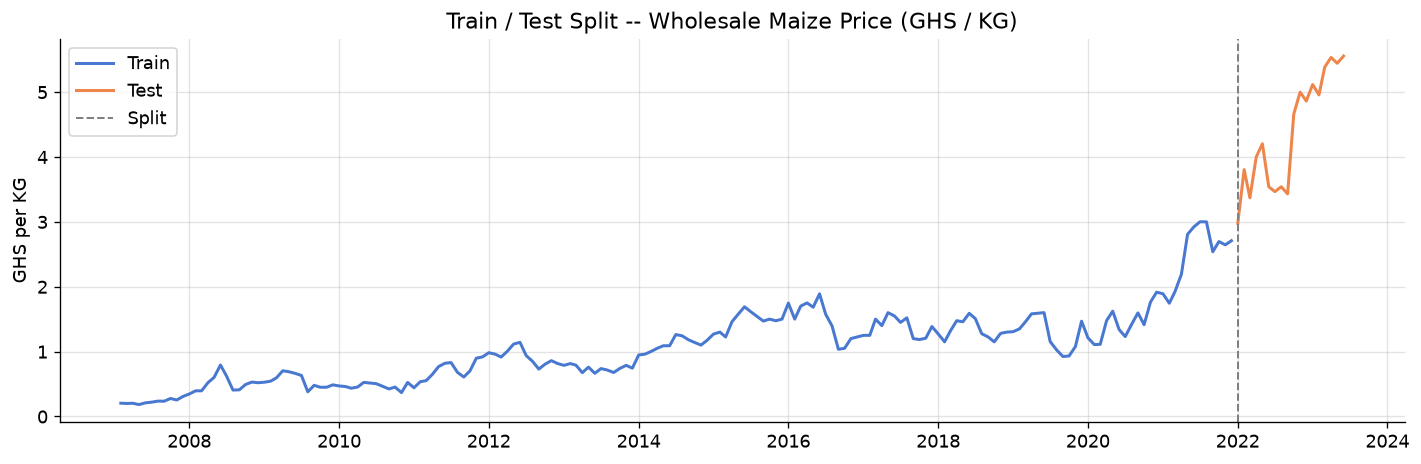

In [19]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train.index, np.expm1(y_train), color=PALETTE[0], linewidth=1.8, label="Train")
ax.plot(test.index,  np.expm1(y_test),  color=PALETTE[1], linewidth=1.8, label="Test")
ax.axvline(split_date, color="grey", linestyle="--", linewidth=1.2, label="Split")
ax.set_title("Train / Test Split -- Wholesale Maize Price (GHS / KG)")
ax.set_ylabel("GHS per KG")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Save Outputs

In [20]:
# Full feature-engineered dataset
model_df.to_csv(DATA_DIR / "maize_wholesale_features.csv")

# Train and test splits
SAVE_COLS = FINAL_FEATURES + ["log_target", "price_ghs", "target", "outlier_flag", "imputed"]
train[SAVE_COLS].to_csv(DATA_DIR / "train.csv")
test[SAVE_COLS].to_csv(DATA_DIR  / "test.csv")

# Feature config for downstream notebooks
(DATA_DIR / "feature_config.json").write_text(json.dumps({
    "features": FINAL_FEATURES,
    "target": "log_target",
    "target_raw": "price_ghs",
    "test_months": TEST_MONTHS,
    "split_date": str(split_date.date()),
    "notes": (
        "Target and price-level features are log1p transformed. "
        "Invert with np.expm1() to recover GHS/KG."
    )
}, indent=2))

print("Saved:")
for p in sorted(DATA_DIR.iterdir()):
    print(f"  {p.relative_to(PROJECT_ROOT)}  ({p.stat().st_size / 1024:.1f} KB)")

Saved:
  data\feature_config.json  (0.5 KB)
  data\maize_wholesale_features.csv  (77.7 KB)
  data\test.csv  (5.7 KB)
  data\train.csv  (54.5 KB)


## 9. Summary

### 9.1 Steps completed

| Step | Action | Outcome |
|------|--------|---------|
| Series extraction | National monthly median wholesale maize (100 KG) to GHS/KG | 209 months |
| Gap check | Reindex to full monthly grid | Series complete |
| Outlier review | Rolling 3×IQR fence at series level | Flagged, not removed |
| Lag features | Lags 1, 2, 3, 6, 12 months | Direct price memory |
| Rolling stats | 3/6/12-month mean; 3-month std | Trend and volatility |
| Calendar | month (cyclic sin/cos), quarter, year | Seasonal and long-run signals |
| Rate of change | MoM and YoY pct change | Momentum signal |
| Log transform | Applied to price-level features and target | Reduces skew |
| Warm-up drop | 12+ rows with NaN removed | Clean feature matrix |
| Train/test split | Last 18 months held out chronologically | No data leakage |

### 9.2 Phase 3 outline

- Load `data/train.csv` and `data/test.csv`
- Train an **XGBoost regressor** on `log_target`
- Use time-series cross-validation (walk-forward) for hyperparameter tuning
- Evaluate on the held-out test set in Phase 4

### 9.3 Limitations

- The model targets the national median —individual market conditions are not captured.
- All data ends July 2023; forecasts beyond that date extrapolate from historical patterns.
- The 2022 inflation spike is split across train and test windows —the evaluation should assess whether the model generalises to extreme price levels
  or captures only smooth trend continuation.

In [21]:
con.close()
print("Done. DuckDB connection closed.")

Done. DuckDB connection closed.
